In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
data=np.loadtxt('ex2data2.txt',delimiter=',')
data.shape

(118, 3)

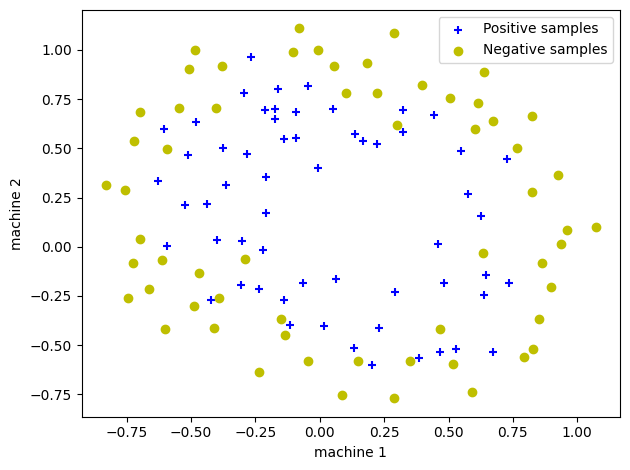

In [3]:
#plotting

pos = np.where(data[:,2]==1)
neg = np.where(data[:,2]==0)

plt.figure()
plt.scatter(data[pos,0],data[pos,1],marker='+',c='b',label='Positive samples')
plt.scatter(data[neg,0],data[neg,1],marker='o',c='y',label='Negative samples')
plt.legend()
plt.xlabel('machine 1')
plt.ylabel('machine 2')
plt.tight_layout()

In [4]:
X=data[:,:2]
y=data[:,2]

db seems to be non linear . we need polynomial features

In [5]:
def poly_features(x1,x2,degree):
    x1=x1.reshape((x1.size,1))
    x2=x2.reshape((x2.size,1))
    result=np.ones(x1[:,0].shape)  
    degree=degree  

    for i in range(1,degree+1):
        for j in range(0,i+1):
            result=np.c_[result,(x1**(i-j))*(x2**j)]

    return result
degree=6
X_poly=poly_features(X[:,0],X[:,1],degree)
X_poly[:,0]

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [6]:
#scaling
X_bias_col=X_poly[:,[0]]
X_features=X_poly[:,1:]
mu=X_features.mean(axis=0)
sigma=X_features.std(axis=0,ddof=1)
X_features_scaled=(X_features-mu)/sigma
X_scaled_full=np.c_[X_bias_col,X_features_scaled]
X_scaled_full.shape

(118, 28)

In [7]:
def sigmoid(z):
    return (1/(1+np.exp(-z)))

def compute_cost_grad(x,y,theta,lamb):
    n=y.size
    grad=np.zeros(theta.shape)
    reg_theta=theta[1:]
    hypothesis=sigmoid(x@theta)
    hypothesis=np.clip(hypothesis,1e-7,1-(1e-7))
    cost=( np.sum(-y*np.log(hypothesis)-(1-y)*np.log(1-hypothesis))/n )+ (lamb/(2*n))*np.sum(reg_theta*reg_theta)
    n_grad=(np.dot(x.T,(hypothesis-y)))/n
    grad[0]=n_grad[0]
    grad[1:]=n_grad[1:]+(lamb/n)*reg_theta

    return cost , grad

def gradientDescent(x,y,theta,alpha,lamb,max_iter):
    theta=theta.copy()
    theta_history= []
    cost_history= []

    for i in range(max_iter):
        # theta=theta.copy()
        cost,grad=compute_cost_grad(x,y,theta,lamb)
        theta -= alpha * grad
        theta_history.append(theta.copy())
        cost_history.append(cost)

    return theta, theta_history,cost_history

max_iter=3000
alpha=0.5
lamb=1
theta_init=np.zeros(X_scaled_full.shape[1])

theta,theta_history,cost_history=gradientDescent(X_scaled_full,y,theta_init,alpha,lamb,max_iter)
theta,cost_history[-1]


(array([-0.52754232,  0.7100889 ,  1.31173142, -0.68783339, -0.90028656,
        -0.94767566,  0.33085358,  0.36528593,  0.14867842,  0.22362427,
        -0.8668865 , -0.13704363, -0.23240258, -0.36806187, -0.90006674,
        -0.14054567, -0.05513606,  0.64620782, -0.28539037, -0.50065971,
        -0.09488972, -0.87659269, -0.03652173, -0.28186879,  0.35582702,
        -0.69210986, -0.41891658, -0.5656639 ]),
 np.float64(0.3658910189405762))

Text(0.5, 1.0, 'Convergence plot')

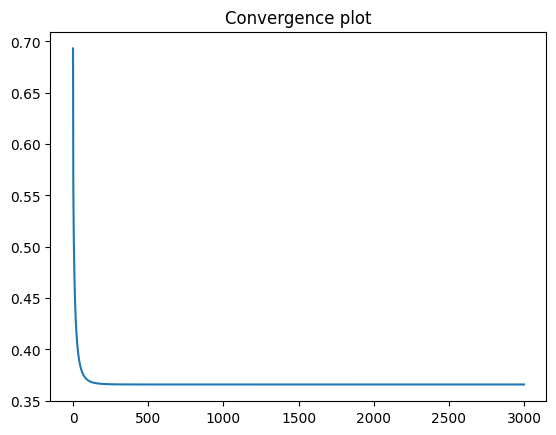

In [8]:
plt.figure()
plt.plot(range(len(cost_history)),cost_history)
plt.title('Convergence plot')

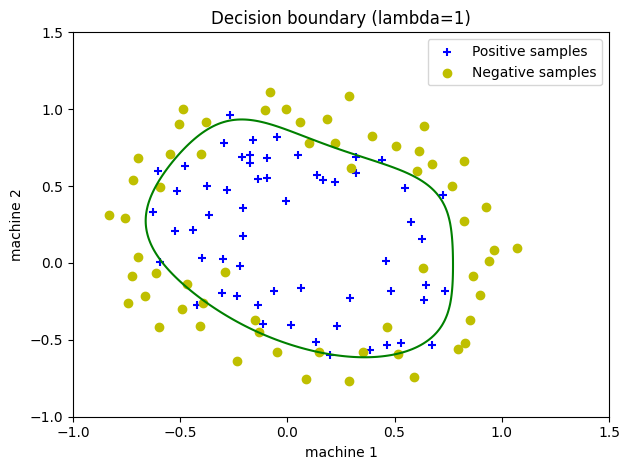

In [9]:
#decision boundary

u = np.linspace(-1, 1.5, 200)
v = np.linspace(-1, 1.5, 200)
U, V = np.meshgrid(u, v)

uv_poly = poly_features(U.ravel(), V.ravel(), degree)
uv_scaled = (uv_poly[:,1:] - mu) / sigma
uv_full = np.c_[uv_poly[:,[0]], uv_scaled]
z = (uv_full @ theta).reshape(U.shape)

plt.figure()
plt.scatter(data[pos,0],data[pos,1],marker='+',c='b',label='Positive samples')
plt.scatter(data[neg,0],data[neg,1],marker='o',c='y',label='Negative samples')
plt.contour(u,v,z,levels=[0],colors='g')
plt.legend()
plt.xlabel('machine 1')
plt.ylabel('machine 2')
plt.title(f'Decision boundary (lambda={lamb})')
plt.tight_layout()
plt.show()